## Progetto 2 del Modulo 3

In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_linnerud
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error, r2_score

## Caricamento Dataset e preparazione variabili X ed Y

In [56]:
linnerud = load_linnerud(as_frame=True)
df=linnerud.frame
X=df[linnerud.feature_names]
y=df[linnerud.target_names]

print(df.describe())

#Standardizzazione
scaler = StandardScaler()
X_std =scaler.fit_transform(X)
y_std=scaler.fit_transform(y)

y_std_df=pd.DataFrame(y_std, columns=linnerud.target_names)

#Applicazione PCA per ridurre numero target
pca = PCA(n_components=1)
y_pca = pca.fit_transform(y_std)


#Scelta manuale del target
y_manuale=y_std_df['Waist']


           Chins      Situps      Jumps      Weight      Waist      Pulse
count  20.000000   20.000000   20.00000   20.000000  20.000000  20.000000
mean    9.450000  145.550000   70.30000  178.600000  35.400000  56.100000
std     5.286278   62.566575   51.27747   24.690505   3.201973   7.210373
min     1.000000   50.000000   25.00000  138.000000  31.000000  46.000000
25%     4.750000  101.000000   39.50000  160.750000  33.000000  51.500000
50%    11.500000  122.500000   54.00000  176.000000  35.000000  55.000000
75%    13.250000  210.000000   85.25000  191.500000  37.000000  60.500000
max    17.000000  251.000000  250.00000  247.000000  46.000000  74.000000


## Fase di addestramento e valutazione

In [32]:
#Linear Regression
linear1 = LinearRegression()
linear1.fit(X_std, y_pca)

linear2 = LinearRegression()
linear2.fit(X_std, y_manuale)


#Ridge
ridge1 = Ridge(alpha=1)
ridge1.fit(X_std, y_pca)

ridge2 = Ridge(alpha=1)
ridge2.fit(X_std, y_manuale)


#Lasso
lasso1 = Lasso(alpha=0.1)
lasso1.fit(X_std, y_pca)

lasso2 = Lasso(alpha=0.1)
lasso2.fit(X_std, y_manuale)

,"alpha alpha: float, default=1.0Constant that multiplies the L1 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Lasso` object is not advised.Instead, you should use the :class:`LinearRegression` object.",0.1
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.",False
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary <warm_start>`.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'
Name,Type,Value


In [39]:
y_pred_linear1 = linear1.predict(X_std)
y_pred_linear2 = linear2.predict(X_std)

#MSE Linear Regression
mse1 = mean_squared_error(y_pca, y_pred_linear1)
print(f'MSE: {mse1:.3f}')

mse2 = mean_squared_error(y_manuale, y_pred_linear2)
print(f'MSE: {mse2:.3f}')

#R2 Linear Regression
r2_1=r2_score(y_pca, y_pred_linear1)
print(f'R2_1: {r2_1:.3f}')

r2_2=r2_score(y_manuale, y_pred_linear2)
print(f'R2_2: {r2_2:.3f}')

MSE: 1.269
MSE: 0.452
R2_1: 0.397
R2_2: 0.548


In [40]:
y_pred_ridge1 = ridge1.predict(X_std)
y_pred_ridge2 = ridge2.predict(X_std)

#MSE Ridge
mse1r = mean_squared_error(y_pca, y_pred_ridge1)
print(f'MSE: {mse1r:.3f}')

mse2r = mean_squared_error(y_manuale, y_pred_ridge2)
print(f'MSE: {mse2r:.3f}')

#R2 Ridge
r2_1r=r2_score(y_pca, y_pred_ridge1)
print(f'R2_1: {r2_1r:.3f}')

r2_2r=r2_score(y_manuale, y_pred_ridge2)
print(f'R2_2: {r2_2r:.3f}')

MSE: 1.276
MSE: 0.457
R2_1: 0.394
R2_2: 0.543


In [ ]:
y_pred_lasso1 = lasso1.predict(X_std)
y_pred_lasso2 = lasso2.predict(X_std)

#MSE Lasso
mse1l = mean_squared_error(y_pca, y_pred_lasso1)
print(f'MSE: {mse1l:.3f}')

mse2l = mean_squared_error(y_manuale, y_pred_lasso2)
print(f'MSE: {mse2l:.3f}')

#R2 Lasso
r2_1l=r2_score(y_pca, y_pred_lasso1)
print(f'R2_1: {r2_1l:.3f}')

r2_2l=r2_score(y_manuale, y_pred_lasso2)
print(f'R2_2: {r2_2l:.3f}')

MSE: 1.332
MSE: 0.516
R2_1: 0.367
R2_2: 0.484


## Analisi e Visualizzazione

In [50]:
pca_frature = PCA(n_components=2)
X_pca = pca_frature.fit_transform(X_std)

pc1_feature = X_pca[:,[0]]
pc2_feature = X_pca[:, [1]]

In [53]:
#Linear Regression con PCA
linear_pca = LinearRegression()
linear_pca.fit(pc1_feature, y_pca)

#Ridge con PCA
ridge_pca = Ridge(alpha=1)
ridge_pca.fit(pc1_feature, y_pca)
 
#Lasso con PCA
lasso_pca = Lasso(alpha=0.1)
lasso_pca.fit(pc1_feature, y_pca)

,"alpha alpha: float, default=1.0Constant that multiplies the L1 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Lasso` object is not advised.Instead, you should use the :class:`LinearRegression` object.",0.1
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.",False
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary <warm_start>`.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'
Name,Type,Value


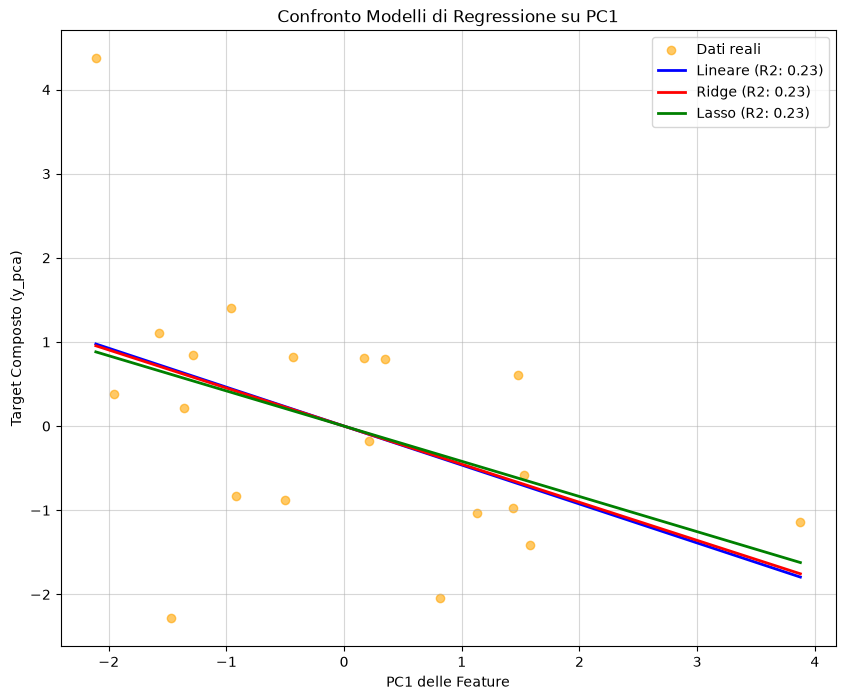

In [59]:
plt.figure(figsize=(10, 8))

# A. Scatter plot dei punti reali (Asse X = PC1 delle feature, Asse Y = y_pca)
plt.scatter(pc1_feature, y_pca, color='orange', alpha=0.6, label='Dati reali')

# B. Ordine PC1 per tracciare le rette in modo pulito
sorted_indices = np.argsort(pc1_feature.ravel())
pc1_sorted = pc1_feature[sorted_indices]

# C. Calcolo predizioni ordinate per ciascuno dei 3 modelli
pred_linear = linear_pca.predict(pc1_sorted)
pred_ridge = ridge_pca.predict(pc1_sorted)
pred_lasso = lasso_pca.predict(pc1_sorted)

# Calcolo degli R2 finali da mettere nelle etichette (puoi usare r2_score)
r2_lin = r2_score(y_pca, linear_pca.predict(pc1_feature))
r2_rid = r2_score(y_pca, ridge_pca.predict(pc1_feature))
r2_las = r2_score(y_pca, lasso_pca.predict(pc1_feature))

# D. Tracciamento delle tre rette di regressione
plt.plot(pc1_sorted, pred_linear, color='blue', linewidth=2, label=f'Lineare (R2: {r2_lin:.2f})')
plt.plot(pc1_sorted, pred_ridge, color='red', linewidth=2, label=f'Ridge (R2: {r2_rid:.2f})')
plt.plot(pc1_sorted, pred_lasso, color='green', linewidth=2, label=f'Lasso (R2: {r2_las:.2f})')

# E. Creazione grafico con titoli, etichette e legenda
plt.xlabel('PC1 delle Feature')
plt.ylabel('Target Composto (y_pca)')
plt.title('Confronto Modelli di Regressione su PC1')
plt.legend()
plt.grid(True, alpha=0.5)

plt.show()